In [13]:
# ============================================
# Skin Lesion Segmentation (ISIC dataset)
# U-Net with a PRETRAINED MobileNetV2 encoder (transfer learning)
#
# Expected dataset structure:
#   dataset/images/*.jpg   -> skin lesion photos
#   dataset/masks/*.png    -> binary masks (lesion = white, background = black)
#
# Common Kaggle datasets: search "ISIC 2018 skin lesion segmentation"
# ============================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
import kagglehub

# ----------------------------------------------------
# STEP 1: Download dataset from Kaggle and set paths
# ----------------------------------------------------

# Download latest version
path = kagglehub.dataset_download("mosharofhossain/isic-2017-skin-lesion-segmentation-dataset")
print("Path to dataset files:", path)

# Walk the full tree upfront so we don't have to guess folder names blind
# (every folder that actually contains files, with a sample filename)
print("\nFolder structure:")
for root, dirs, files in os.walk(path):
    if files:
        print(root, "->", len(files), "files, e.g.", files[0])

# UPDATE THESE once you see the real structure printed above:
IMAGES_DIR = os.path.join(path, "images")   # <-- update if the folder name differs
MASKS_DIR = os.path.join(path, "masks")     # <-- update if the folder name differs

IMG_SIZE = (128, 128)   # MobileNetV2 works with any size divisible by 32; 128 keeps training fast
BATCH_SIZE = 16

# ----------------------------------------------------
# STEP 2: Build file lists and train/val split
# ----------------------------------------------------

image_files = sorted(os.listdir(IMAGES_DIR))
mask_files = sorted(os.listdir(MASKS_DIR))

assert len(image_files) == len(mask_files), "Image/mask count mismatch!"

image_paths = [os.path.join(IMAGES_DIR, f) for f in image_files]
mask_paths = [os.path.join(MASKS_DIR, f) for f in mask_files]

split_idx = int(0.85 * len(image_paths))
train_img_paths, val_img_paths = image_paths[:split_idx], image_paths[split_idx:]
train_mask_paths, val_mask_paths = mask_paths[:split_idx], mask_paths[split_idx:]

print(f"Train samples: {len(train_img_paths)}, Val samples: {len(val_img_paths)}")

# ----------------------------------------------------
# STEP 3: Data loading pipeline
# ----------------------------------------------------

def load_image_mask(img_path, mask_path):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0

    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)
    mask = tf.image.resize(mask, IMG_SIZE, method='nearest')
    mask = tf.cast(mask > 127, tf.float32)   # binarize: lesion = 1, background = 0

    return img, mask

def make_dataset(img_paths, mask_paths, training=False):
    ds = tf.data.Dataset.from_tensor_slices((img_paths, mask_paths))
    ds = ds.map(load_image_mask, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(200)
    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_img_paths, train_mask_paths, training=True)
val_ds = make_dataset(val_img_paths, val_mask_paths, training=False)

# ----------------------------------------------------
# STEP 4: Visualize a sample image + mask
# ----------------------------------------------------

for imgs, masks in train_ds.take(1):
    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(imgs[0])
    plt.title("Input Image")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(masks[0][:, :, 0], cmap='gray')
    plt.title("Ground Truth Mask")
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    break

# ----------------------------------------------------
# STEP 5: Build U-Net with a PRETRAINED MobileNetV2 encoder
# ----------------------------------------------------
# Instead of training an encoder from scratch (like the previous project),
# we reuse MobileNetV2's ImageNet-pretrained weights as the downsampling
# path, and only train the decoder (upsampling path) + fine-tune the
# encoder's later layers. This converges faster and works well even with
# a modest amount of medical image data.

def build_unet_pretrained(input_shape=(128, 128, 3)):
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=input_shape, include_top=False, weights='imagenet'
    )

    # Pick skip-connection layers from the pretrained encoder
    skip_names = [
        'block_1_expand_relu',   # 64x64
        'block_3_expand_relu',   # 32x32
        'block_6_expand_relu',   # 16x16
        'block_13_expand_relu',  # 8x8
    ]
    skip_outputs = [base_model.get_layer(name).output for name in skip_names]
    bottleneck_output = base_model.get_layer('block_16_project').output  # 4x4

    encoder = models.Model(inputs=base_model.input,
                            outputs=skip_outputs + [bottleneck_output])
    encoder.trainable = False   # freeze pretrained weights initially

    inputs = layers.Input(shape=input_shape)
    s1, s2, s3, s4, bn = encoder(inputs)

    # Decoder (upsampling path), mirrors standard U-Net but skips connect
    # to the pretrained encoder's intermediate activations
    def decoder_block(x, skip, filters):
        x = layers.Conv2DTranspose(filters, 3, strides=2, padding='same')(x)
        x = layers.Concatenate()([x, skip])
        x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)
        return x

    d1 = decoder_block(bn, s4, 256)   # 4x4  -> 8x8
    d2 = decoder_block(d1, s3, 128)   # 8x8  -> 16x16
    d3 = decoder_block(d2, s2, 64)    # 16x16 -> 32x32
    d4 = decoder_block(d3, s1, 32)    # 32x32 -> 64x64

    # Final upsample back to full input resolution
    outputs = layers.Conv2DTranspose(16, 3, strides=2, padding='same', activation='relu')(d4)  # 128x128
    outputs = layers.Conv2D(1, 1, activation='sigmoid')(outputs)   # binary mask

    model = models.Model(inputs, outputs, name="UNet_MobileNetV2")
    return model, encoder

model, encoder = build_unet_pretrained(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
model.summary()

# ----------------------------------------------------
# STEP 6: Loss & Metrics (Dice + Binary Crossentropy)
# ----------------------------------------------------

def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1 - dice_coef(y_true, y_pred)

def combined_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)

# ----------------------------------------------------
# STEP 7: Phase 1 - Train decoder only (encoder frozen)
# ----------------------------------------------------

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=combined_loss,
    metrics=['accuracy', dice_coef]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=6, restore_best_weights=True
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6
)

print("\n=== Phase 1: Training decoder with frozen pretrained encoder ===")
history1 = model.fit(
    train_ds,
    epochs=20,
    validation_data=val_ds,
    callbacks=[early_stop, reduce_lr]
)

# ----------------------------------------------------
# STEP 8: Phase 2 - Fine-tune the encoder (unfreeze, lower LR)
# ----------------------------------------------------

encoder.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # much lower LR for fine-tuning
    loss=combined_loss,
    metrics=['accuracy', dice_coef]
)

print("\n=== Phase 2: Fine-tuning pretrained encoder ===")
history2 = model.fit(
    train_ds,
    epochs=15,
    validation_data=val_ds,
    callbacks=[early_stop, reduce_lr]
)

# ----------------------------------------------------
# STEP 9: Evaluate
# ----------------------------------------------------

val_loss, val_acc, val_dice = model.evaluate(val_ds)
print(f"\nValidation Accuracy: {val_acc*100:.2f}%, Dice Coefficient: {val_dice:.4f}")

# ----------------------------------------------------
# STEP 10: Plot combined training history (both phases)
# ----------------------------------------------------

def merge_history(h1, h2, key):
    return h1.history[key] + h2.history[key]

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.plot(merge_history(history1, history2, 'loss'), label='Train Loss')
plt.plot(merge_history(history1, history2, 'val_loss'), label='Val Loss')
plt.axvline(x=len(history1.history['loss']), color='gray', linestyle='--', label='Fine-tune start')
plt.title('Loss over Epochs')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(merge_history(history1, history2, 'accuracy'), label='Train Accuracy')
plt.plot(merge_history(history1, history2, 'val_accuracy'), label='Val Accuracy')
plt.axvline(x=len(history1.history['loss']), color='gray', linestyle='--')
plt.title('Pixel Accuracy over Epochs')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(merge_history(history1, history2, 'dice_coef'), label='Train Dice')
plt.plot(merge_history(history1, history2, 'val_dice_coef'), label='Val Dice')
plt.axvline(x=len(history1.history['loss']), color='gray', linestyle='--')
plt.title('Dice Coefficient over Epochs')
plt.legend()

plt.tight_layout()
plt.show()

# ----------------------------------------------------
# STEP 11: Visualize Predictions on Validation Images
# ----------------------------------------------------

for imgs, masks in val_ds.take(1):
    preds = model.predict(imgs)
    preds_binary = (preds > 0.5).astype(np.float32)

    plt.figure(figsize=(12, 8))
    for i in range(min(4, imgs.shape[0])):
        plt.subplot(4, 3, i * 3 + 1)
        plt.imshow(imgs[i])
        plt.title("Input")
        plt.axis('off')

        plt.subplot(4, 3, i * 3 + 2)
        plt.imshow(masks[i][:, :, 0], cmap='gray')
        plt.title("Ground Truth")
        plt.axis('off')

        plt.subplot(4, 3, i * 3 + 3)
        plt.imshow(preds_binary[i][:, :, 0], cmap='gray')
        plt.title("Prediction")
        plt.axis('off')
    plt.tight_layout()
    plt.show()
    break

# ----------------------------------------------------
# STEP 12: Save the Model
# ----------------------------------------------------

model.save('skin_lesion_segmentation_unet_mobilenetv2.keras')
print("Model saved successfully!")

100%|██████████| 11.3G/11.3G [02:57<00:00, 68.7MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/mosharofhossain/isic-2017-skin-lesion-segmentation-dataset/versions/1

Folder structure:
/root/.cache/kagglehub/datasets/mosharofhossain/isic-2017-skin-lesion-segmentation-dataset/versions/1/ISIC_2017 -> 3 files, e.g. ISIC-2017_Validation_Data_metadata.csv
/root/.cache/kagglehub/datasets/mosharofhossain/isic-2017-skin-lesion-segmentation-dataset/versions/1/ISIC_2017/training_images -> 2000 files, e.g. ISIC_0008236.jpg
/root/.cache/kagglehub/datasets/mosharofhossain/isic-2017-skin-lesion-segmentation-dataset/versions/1/ISIC_2017/test_masks -> 600 files, e.g. ISIC_0016026_segmentation.png
/root/.cache/kagglehub/datasets/mosharofhossain/isic-2017-skin-lesion-segmentation-dataset/versions/1/ISIC_2017/val_masks -> 150 files, e.g. ISIC_0012204_segmentation.png
/root/.cache/kagglehub/datasets/mosharofhossain/isic-2017-skin-lesion-segmentation-dataset/versions/1/ISIC_2017/test_images -> 600 files, e.g. ISIC_0014958.jpg
/root/.cache/kaggleh

FileNotFoundError: [Errno 2] No such file or directory: '/root/.cache/kagglehub/datasets/mosharofhossain/isic-2017-skin-lesion-segmentation-dataset/versions/1/images'

Path to dataset files: /root/.cache/kagglehub/datasets/mosharofhossain/isic-2017-skin-lesion-segmentation-dataset/versions/1

Folder structure:
/root/.cache/kagglehub/datasets/mosharofhossain/isic-2017-skin-lesion-segmentation-dataset/versions/1/ISIC_2017 -> 3 files, e.g. ISIC-2017_Validation_Data_metadata.csv
/root/.cache/kagglehub/datasets/mosharofhossain/isic-2017-skin-lesion-segmentation-dataset/versions/1/ISIC_2017/training_images -> 2000 files, e.g. ISIC_0008236.jpg
/root/.cache/kagglehub/datasets/mosharofhossain/isic-2017-skin-lesion-segmentation-dataset/versions/1/ISIC_2017/test_masks -> 600 files, e.g. ISIC_0016026_segmentation.png
/root/.cache/kagglehub/datasets/mosharofhossain/isic-2017-skin-lesion-segmentation-dataset/versions/1/ISIC_2017/val_masks -> 150 files, e.g. ISIC_0012204_segmentation.png
/root/.cache/kagglehub/datasets/mosharofhossain/isic-2017-skin-lesion-segmentation-dataset/versions/1/ISIC_2017/test_images -> 600 files, e.g. ISIC_0014958.jpg
/root/.cache/kaggleh

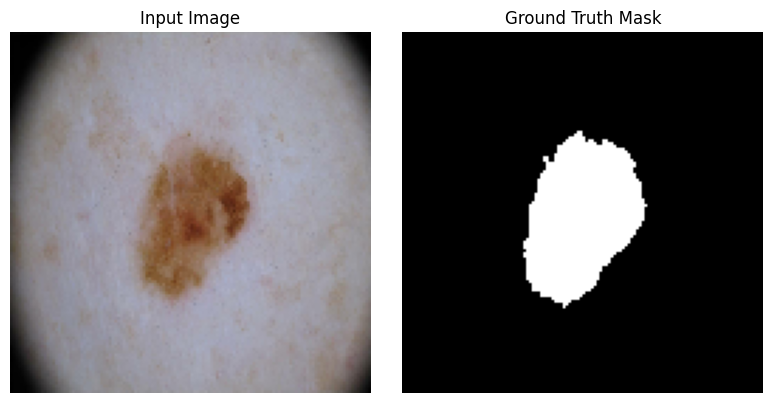

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "UNet_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional          │ [(None, 64, 64,   │  1,841,984 │ input_layer_1[0]… │
│ (Functional)        │ 96), (None, 32,   │            │                   │
│                     │ 32, 144), (None,  │            │                   │
│                     │ 16, 16, 192),     │            │                   │
│                     │ (None, 8, 8,      │            │                   │
│                     │ 576), (None, 4,   │            │                   │
│                     │ 4, 320)]          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 8, 8, 256) │    737,536 │ functional[0][4]  │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 8, 8, 832) │          0 │ conv2d_transpose… │
│ (Concatenate)       │                   │            │ functional[0][3]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 8, 8, 256) │  1,917,184 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 8, 8, 256) │      1,024 │ conv2d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 8, 8, 256) │    590,080 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 256) │      1,024 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 16, 16,    │    295,040 │ batch_normalizat… │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 16, 16,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 320)              │            │ functional[0][2]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 16, 16,    │    368,768 │ concatenate_1[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │    147,584 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_2  │ (None, 32, 32,    │     73,792 │ batch_normalizat… │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 32, 32,    │          0 │ conv2d_transpose

 Total params: 6,201,857 (23.66 MB)

 Trainable params: 4,357,953 (16.62 MB)

 Non-trainable params: 1,843,904 (7.03 MB)


=== Phase 1: Training decoder with frozen pretrained encoder ===
Epoch 1/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 459s 4s/step - accuracy: 0.9241 - dice_coef: 0.7068 - loss: 0.5169 - val_accuracy: 0.2689 - val_dice_coef: 0.3086 - val_loss: 12.3003 - learning_rate: 0.0010
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 444s 4s/step - accuracy: 0.9462 - dice_coef: 0.7978 - loss: 0.3615 - val_accuracy: 0.8116 - val_dice_coef: 0.6021 - val_loss: 1.6164 - learning_rate: 0.0010
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 428s 3s/step - accuracy: 0.9495 - dice_coef: 0.8174 - loss: 0.3356 - val_accuracy: 0.4558 - val_dice_coef: 0.3710 - val_loss: 3.3107 - learning_rate: 0.0010
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 457s 4s/step - accuracy: 0.9514 - dice_coef: 0.8243 - loss: 0.3250 - val_accuracy: 0.8043 - val_dice_coef: 0.6222 - val_loss: 1.0731 - learning_rate: 0.0010
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 449s 4s/step - accuracy: 0.9528 - dice_coef: 0.8285 - loss: 0.3152 - val_accuracy: 0.5781 - val_dice_coef

In [ ]:
# ============================================
# Skin Lesion Segmentation (ISIC dataset)
# U-Net with a PRETRAINED MobileNetV2 encoder (transfer learning)
#
# Expected dataset structure:
#   dataset/images/*.jpg   -> skin lesion photos
#   dataset/masks/*.png    -> binary masks (lesion = white, background = black)
#
# Common Kaggle datasets: search "ISIC 2018 skin lesion segmentation"
# ============================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
import kagglehub

# ----------------------------------------------------
# STEP 1: Download dataset from Kaggle and set paths
# ----------------------------------------------------

# Download latest version
path = kagglehub.dataset_download("mosharofhossain/isic-2017-skin-lesion-segmentation-dataset")
print("Path to dataset files:", path)

# Walk the full tree upfront so we don't have to guess folder names blind
# (every folder that actually contains files, with a sample filename)
print("\nFolder structure:")
for root, dirs, files in os.walk(path):
    if files:
        print(root, "->", len(files), "files, e.g.", files[0])

# UPDATE THESE once you see the real structure printed above:
ISIC_ROOT = os.path.join(path, "ISIC_2017")

TRAIN_IMAGES_DIR = os.path.join(ISIC_ROOT, "training_images")
TRAIN_MASKS_DIR = os.path.join(ISIC_ROOT, "training_masks")
VAL_IMAGES_DIR = os.path.join(ISIC_ROOT, "val_images")
VAL_MASKS_DIR = os.path.join(ISIC_ROOT, "val_masks")
TEST_IMAGES_DIR = os.path.join(ISIC_ROOT, "test_images")
TEST_MASKS_DIR = os.path.join(ISIC_ROOT, "test_masks")

IMG_SIZE = (128, 128)   # MobileNetV2 works with any size divisible by 32; 128 keeps training fast
BATCH_SIZE = 16

# ----------------------------------------------------
# STEP 2: Build file lists (dataset already has train/val/test split)
# ----------------------------------------------------

def list_paired_paths(images_dir, masks_dir):
    image_files = sorted(os.listdir(images_dir))
    mask_files = sorted(os.listdir(masks_dir))
    assert len(image_files) == len(mask_files), \
        f"Mismatch in {images_dir}: {len(image_files)} images vs {len(mask_files)} masks"
    image_paths = [os.path.join(images_dir, f) for f in image_files]
    mask_paths = [os.path.join(masks_dir, f) for f in mask_files]
    return image_paths, mask_paths

train_img_paths, train_mask_paths = list_paired_paths(TRAIN_IMAGES_DIR, TRAIN_MASKS_DIR)
val_img_paths, val_mask_paths = list_paired_paths(VAL_IMAGES_DIR, VAL_MASKS_DIR)
test_img_paths, test_mask_paths = list_paired_paths(TEST_IMAGES_DIR, TEST_MASKS_DIR)

print(f"Train samples: {len(train_img_paths)}")
print(f"Val samples: {len(val_img_paths)}")
print(f"Test samples: {len(test_img_paths)}")

# ----------------------------------------------------
# STEP 3: Data loading pipeline
# ----------------------------------------------------

def load_image_mask(img_path, mask_path):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0

    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)
    mask = tf.image.resize(mask, IMG_SIZE, method='nearest')
    mask = tf.cast(mask > 127, tf.float32)   # binarize: lesion = 1, background = 0

    return img, mask

def make_dataset(img_paths, mask_paths, training=False):
    ds = tf.data.Dataset.from_tensor_slices((img_paths, mask_paths))
    ds = ds.map(load_image_mask, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(200)
    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_img_paths, train_mask_paths, training=True)
val_ds = make_dataset(val_img_paths, val_mask_paths, training=False)
test_ds = make_dataset(test_img_paths, test_mask_paths, training=False)

# ----------------------------------------------------
# STEP 4: Visualize a sample image + mask
# ----------------------------------------------------

for imgs, masks in train_ds.take(1):
    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(imgs[0])
    plt.title("Input Image")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(masks[0][:, :, 0], cmap='gray')
    plt.title("Ground Truth Mask")
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    break

# ----------------------------------------------------
# STEP 5: Build U-Net with a PRETRAINED MobileNetV2 encoder
# ----------------------------------------------------
# Instead of training an encoder from scratch (like the previous project),
# we reuse MobileNetV2's ImageNet-pretrained weights as the downsampling
# path, and only train the decoder (upsampling path) + fine-tune the
# encoder's later layers. This converges faster and works well even with
# a modest amount of medical image data.

def build_unet_pretrained(input_shape=(128, 128, 3)):
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=input_shape, include_top=False, weights='imagenet'
    )

    # Pick skip-connection layers from the pretrained encoder
    skip_names = [
        'block_1_expand_relu',   # 64x64
        'block_3_expand_relu',   # 32x32
        'block_6_expand_relu',   # 16x16
        'block_13_expand_relu',  # 8x8
    ]
    skip_outputs = [base_model.get_layer(name).output for name in skip_names]
    bottleneck_output = base_model.get_layer('block_16_project').output  # 4x4

    encoder = models.Model(inputs=base_model.input,
                            outputs=skip_outputs + [bottleneck_output])
    encoder.trainable = False   # freeze pretrained weights initially

    inputs = layers.Input(shape=input_shape)
    s1, s2, s3, s4, bn = encoder(inputs)

    # Decoder (upsampling path), mirrors standard U-Net but skips connect
    # to the pretrained encoder's intermediate activations
    def decoder_block(x, skip, filters):
        x = layers.Conv2DTranspose(filters, 3, strides=2, padding='same')(x)
        x = layers.Concatenate()([x, skip])
        x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)
        return x

    d1 = decoder_block(bn, s4, 256)   # 4x4  -> 8x8
    d2 = decoder_block(d1, s3, 128)   # 8x8  -> 16x16
    d3 = decoder_block(d2, s2, 64)    # 16x16 -> 32x32
    d4 = decoder_block(d3, s1, 32)    # 32x32 -> 64x64

    # Final upsample back to full input resolution
    outputs = layers.Conv2DTranspose(16, 3, strides=2, padding='same', activation='relu')(d4)  # 128x128
    outputs = layers.Conv2D(1, 1, activation='sigmoid')(outputs)   # binary mask

    model = models.Model(inputs, outputs, name="UNet_MobileNetV2")
    return model, encoder

model, encoder = build_unet_pretrained(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
model.summary()

# ----------------------------------------------------
# STEP 6: Loss & Metrics (Dice + Binary Crossentropy)
# ----------------------------------------------------

def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1 - dice_coef(y_true, y_pred)

def combined_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)

# ----------------------------------------------------
# STEP 7: Phase 1 - Train decoder only (encoder frozen)
# ----------------------------------------------------

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=combined_loss,
    metrics=['accuracy', dice_coef]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=6, restore_best_weights=True
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6
)

print("\n=== Phase 1: Training decoder with frozen pretrained encoder ===")
history1 = model.fit(
    train_ds,
    epochs=20,
    validation_data=val_ds,
    callbacks=[early_stop, reduce_lr]
)

# ----------------------------------------------------
# STEP 8: Phase 2 - Fine-tune the encoder (unfreeze, lower LR)
# ----------------------------------------------------

encoder.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # much lower LR for fine-tuning
    loss=combined_loss,
    metrics=['accuracy', dice_coef]
)

print("\n=== Phase 2: Fine-tuning pretrained encoder ===")
history2 = model.fit(
    train_ds,
    epochs=15,
    validation_data=val_ds,
    callbacks=[early_stop, reduce_lr]
)

# ----------------------------------------------------
# STEP 9: Evaluate on the held-out TEST set
# ----------------------------------------------------

test_loss, test_acc, test_dice = model.evaluate(test_ds)
print(f"\nTest Accuracy: {test_acc*100:.2f}%, Dice Coefficient: {test_dice:.4f}")

# ----------------------------------------------------
# STEP 10: Plot combined training history (both phases)
# ----------------------------------------------------

def merge_history(h1, h2, key):
    return h1.history[key] + h2.history[key]

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.plot(merge_history(history1, history2, 'loss'), label='Train Loss')
plt.plot(merge_history(history1, history2, 'val_loss'), label='Val Loss')
plt.axvline(x=len(history1.history['loss']), color='gray', linestyle='--', label='Fine-tune start')
plt.title('Loss over Epochs')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(merge_history(history1, history2, 'accuracy'), label='Train Accuracy')
plt.plot(merge_history(history1, history2, 'val_accuracy'), label='Val Accuracy')
plt.axvline(x=len(history1.history['loss']), color='gray', linestyle='--')
plt.title('Pixel Accuracy over Epochs')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(merge_history(history1, history2, 'dice_coef'), label='Train Dice')
plt.plot(merge_history(history1, history2, 'val_dice_coef'), label='Val Dice')
plt.axvline(x=len(history1.history['loss']), color='gray', linestyle='--')
plt.title('Dice Coefficient over Epochs')
plt.legend()

plt.tight_layout()
plt.show()

# ----------------------------------------------------
# STEP 11: Visualize Predictions on TEST Images
# ----------------------------------------------------

for imgs, masks in test_ds.take(1):
    preds = model.predict(imgs)
    preds_binary = (preds > 0.5).astype(np.float32)

    plt.figure(figsize=(12, 8))
    for i in range(min(4, imgs.shape[0])):
        plt.subplot(4, 3, i * 3 + 1)
        plt.imshow(imgs[i])
        plt.title("Input")
        plt.axis('off')

        plt.subplot(4, 3, i * 3 + 2)
        plt.imshow(masks[i][:, :, 0], cmap='gray')
        plt.title("Ground Truth")
        plt.axis('off')

        plt.subplot(4, 3, i * 3 + 3)
        plt.imshow(preds_binary[i][:, :, 0], cmap='gray')
        plt.title("Prediction")
        plt.axis('off')
    plt.tight_layout()
    plt.show()
    break

# ----------------------------------------------------
# STEP 12: Save the Model
# ----------------------------------------------------

model.save('skin_lesion_segmentation_unet_mobilenetv2.keras')
print("Model saved successfully!")